Enter filter size (odd number): 7
Enter padding (zero/replication): 4


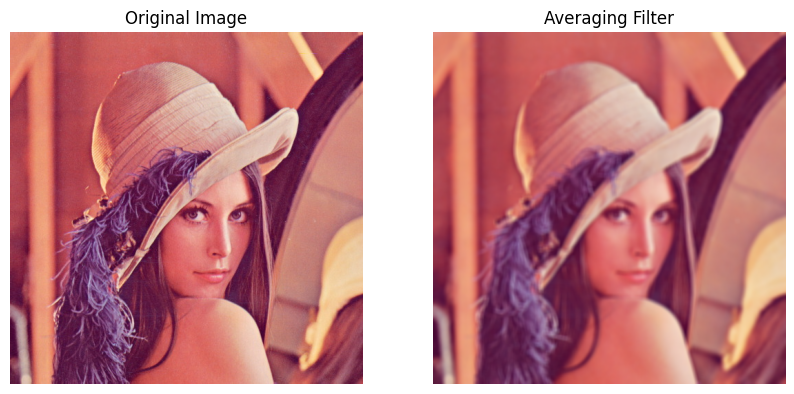

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")
img = cv2.imread("input.jpg")

# Input parameters
n = int(input("Enter filter size (odd number): "))
padding = input("Enter padding (zero/replication): ").lower()

if n < 1 or n % 2 == 0:
    raise ValueError("Filter size must be a positive odd number")

border = cv2.BORDER_CONSTANT if padding == "zero" else cv2.BORDER_REPLICATE

# Averaging filter
kernel = np.ones((n, n), np.float32) / (n * n)
result = cv2.filter2D(img, -1, kernel, borderType=border)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Averaging Filter")
plt.axis("off")
plt.show()


Enter filter size (odd number): 9
Enter padding (zero/replication): 2


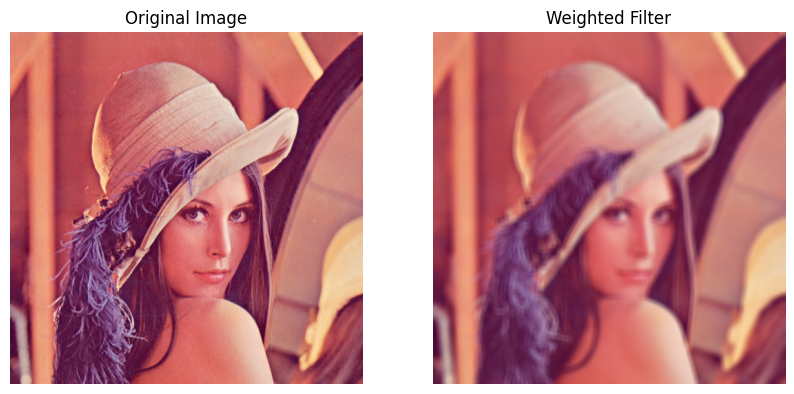

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")
img = cv2.imread("input.jpg")

# Input parameters
n = int(input("Enter filter size (odd number): "))
padding = input("Enter padding (zero/replication): ").lower()

if n < 1 or n % 2 == 0:
    raise ValueError("Filter size must be a positive odd number")

border = cv2.BORDER_CONSTANT if padding == "zero" else cv2.BORDER_REPLICATE

# Construct weighted kernel
c = n // 2
kernel = np.zeros((n, n), dtype=np.float32)

for i in range(n):
    for j in range(n):
        x = i - c
        y = j - c
        kernel[i, j] = max(abs(x), abs(y))

# Avoid zero total weight
kernel[c, c] = 1
kernel = kernel / np.sum(kernel)

# Apply weighted filter
result = cv2.filter2D(img, -1, kernel, borderType=border)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Weighted Filter")
plt.axis("off")
plt.show()


Enter Gaussian filter size (odd number): 5
Enter sigma: 1
Enter padding (zero/replication): 9


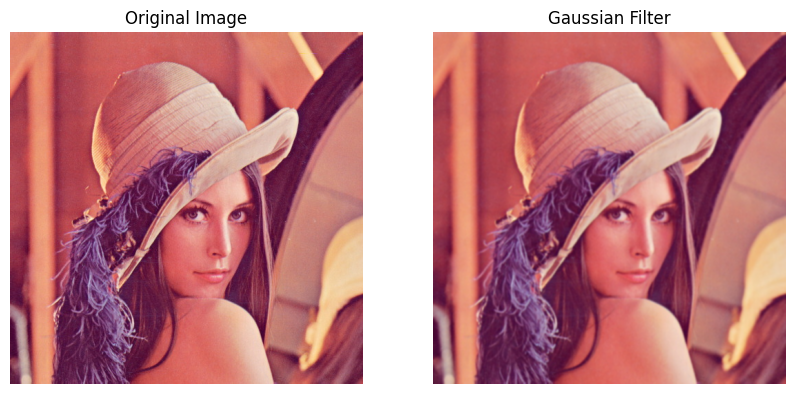

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")
img = cv2.imread("input.jpg")

# Input parameters
n = int(input("Enter Gaussian filter size (odd number): "))
sigma = float(input("Enter sigma: "))
padding = input("Enter padding (zero/replication): ").lower()

if n < 1 or n % 2 == 0:
    raise ValueError("Filter size must be a positive odd number")
if sigma <= 0:
    raise ValueError("Sigma must be positive")

border = cv2.BORDER_CONSTANT if padding == "zero" else cv2.BORDER_REPLICATE

# Apply Gaussian filter
result = cv2.GaussianBlur(
    img, (n, n), sigmaX=sigma, borderType=border
)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter")
plt.axis("off")
plt.show()
